In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
df = pd.read_csv("../data/processed/retail_cleaned.csv")
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
print("Dataset Shape:", df.shape)
print("Total Orders:", df["InvoiceNo"].nunique())
print("Total Revenue;", round(df["Revenue"].sum(), 2))
df.head()

Dataset Shape: (0, 9)
Total Orders: 0
Total Revenue; 0


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue


In [3]:
total_revenue = df["Revenue"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["InvoiceNo"].nunique()

average_order_value = total_revenue / total_orders if total_orders > 0 else 0

print("Total Revenue:", round(total_revenue, 2))
print("Total Quantity Sold:", total_quantity)
print("Total Orders:", total_orders)
print("Average Order Value:", round(average_order_value, 2))

Total Revenue: 0
Total Quantity Sold: 0
Total Orders: 0
Average Order Value: 0


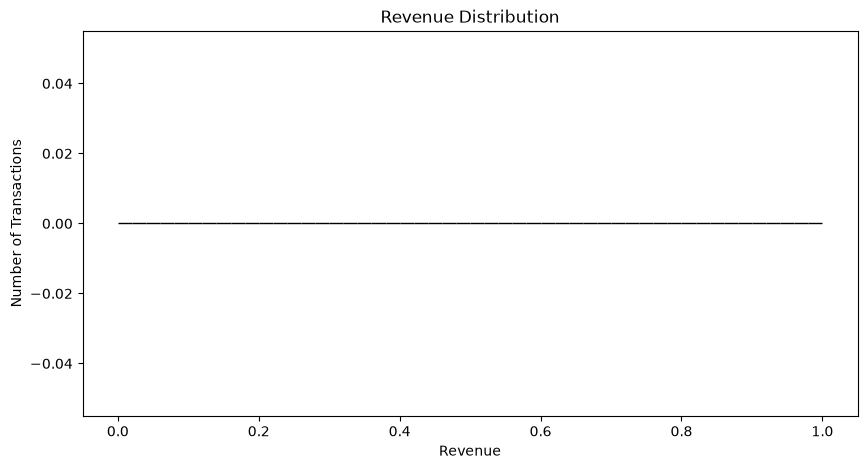

In [4]:
plt.figure(figsize=(10, 5))
sns.histplot(data=df, x="Revenue", bins=50, kde=True)
plt.title("Revenue Distribution")
plt.xlabel("Revenue")
plt.ylabel("Number of Transactions")
plt.show()

In [5]:
top_products = (
df.groupby("Description").agg(
total_quantity=("Quantity", "sum"),
total_revenue=("Revenue", "sum"))
.sort_values("total_quantity", ascending=False)
.head(10))
print(top_products)

Empty DataFrame
Columns: [total_quantity, total_revenue]
Index: []


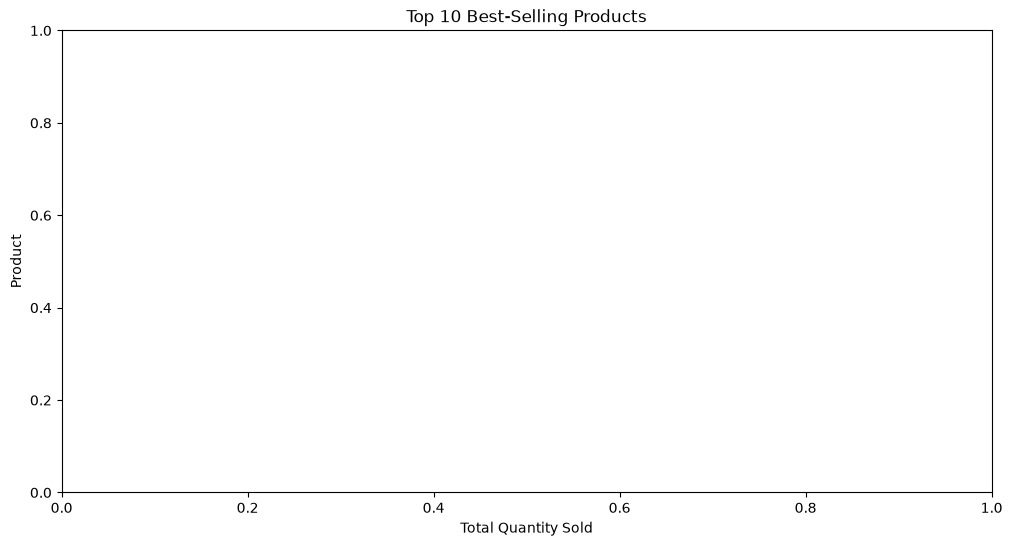

In [6]:
plt.figure(figsize=(12, 6))
sns.barplot(
data=top_products.reset_index(),
x="total_quantity",
y="Description")
plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product")
plt.show()

In [7]:
top_revenue_products = (
df.groupby("Description")["Revenue"]
.sum().sort_values(ascending=False).head(10))
print(top_revenue_products)

Series([], Name: Revenue, dtype: object)


In [9]:
print("Revenue Data Type:", df["Revenue"].dtype)
print(df["Revenue"].head())
print("Top products data type:", top_revenue_products.dtype)


Revenue Data Type: object
Series([], Name: Revenue, dtype: object)
Top products data type: object


In [10]:
df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce")
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")
df = df.dropna(subset=["Revenue", "Quantity"]).copy()

In [11]:
top_revenue_products = (
df.groupby("Description")["Revenue"].sum().nlargest(10))
print(top_revenue_products)

Series([], Name: Revenue, dtype: int64)


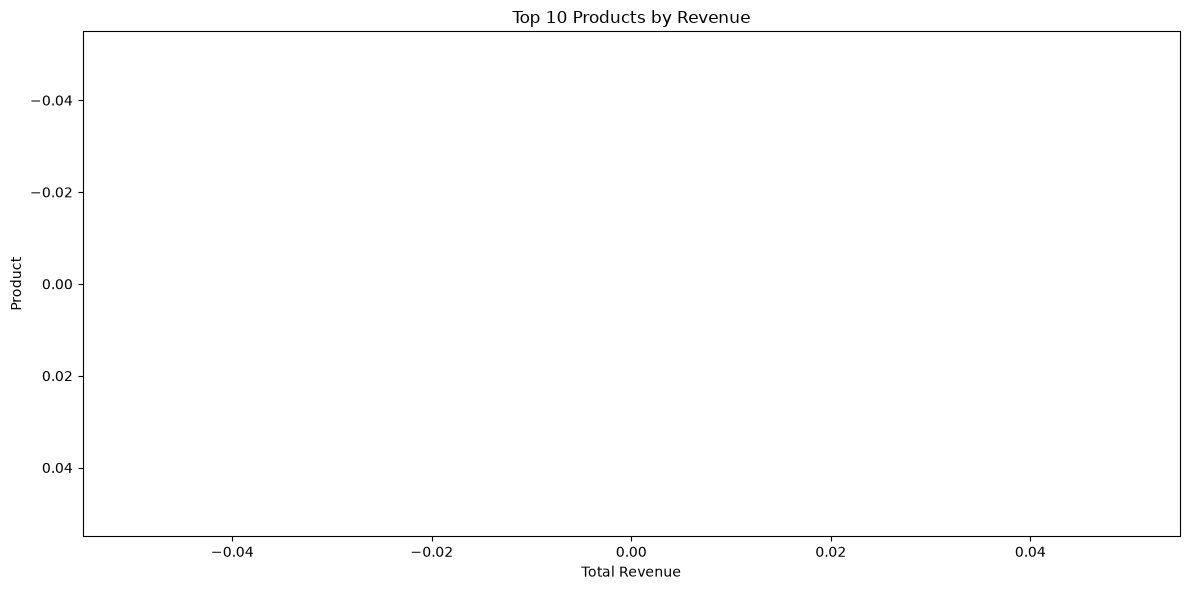

In [12]:
plt.figure(figsize=(12, 6))
plt.barh(
top_revenue_products.index.astype(str),
top_revenue_products.values)
plt.title("Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [13]:
customer_df = df.dropna(subset=["CustomerID"]).copy()
customer_df["CustomerID"] = customer_df["CustomerID"].astype(str)
print("Total Customers:", customer_df["CustomerID"].nunique())
print("Total Customer Transactions:", len(customer_df))

Total Customers: 0
Total Customer Transactions: 0


In [14]:
top_customers = (
customer_df.groupby("CustomerID").agg(
total_spending=("Revenue", "sum"),
total_orders=("InvoiceNo", "nunique")).sort_values("total_spending", ascending=False).head(10))
print(top_customers)

Empty DataFrame
Columns: [total_spending, total_orders]
Index: []


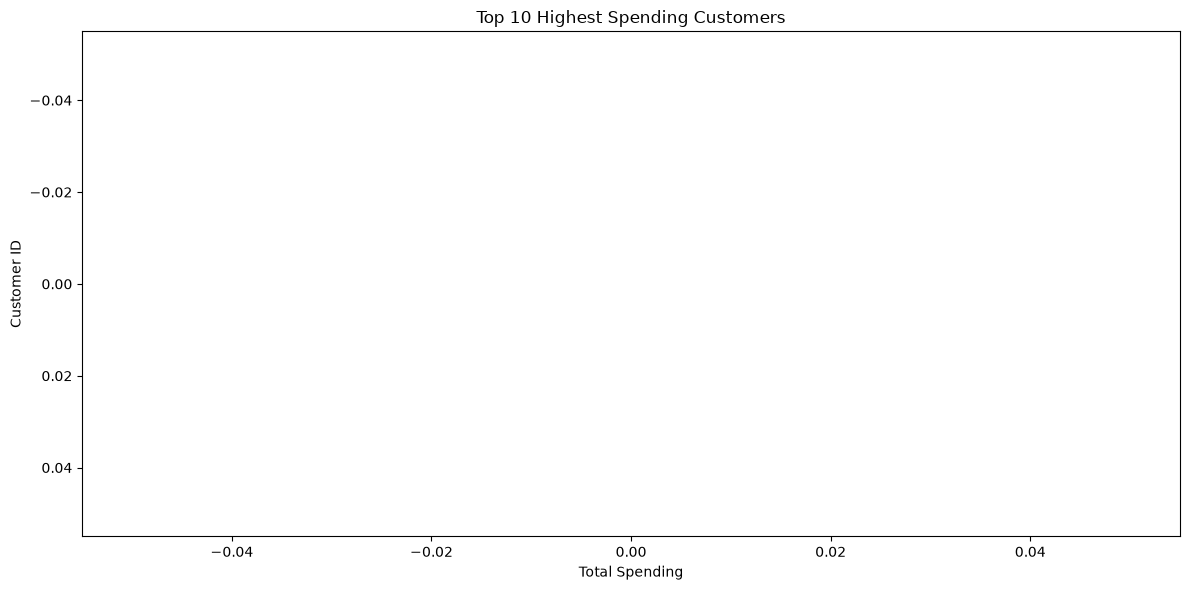

In [15]:
plt.figure(figsize=(12, 6))
plt.barh(
top_customers.index,
top_customers["total_spending"])
plt.title("Top 10 Highest Spending Customers")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [16]:
customer_orders = (
customer_df.groupby("CustomerID")["InvoiceNo"].nunique())
print("Average Orders per Customer:", round(customer_orders.mean(), 2))
print("Maximum Orders by a Customer:", customer_orders.max())
print("Minimum Orders by a Customer:", customer_orders.min())

Average Orders per Customer: nan
Maximum Orders by a Customer: nan
Minimum Orders by a Customer: nan


In [17]:
repeat_customers = (customer_orders > 1).sum()
one_time_customers = (customer_orders == 1).sum()
print("Repeat Customers:", repeat_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customer Percentage:",
round(repeat_customers / len(customer_orders) * 100, 2),"%")

Repeat Customers: 0
One-Time Customers: 0
Repeat Customer Percentage: nan %


C:\Users\pantv\AppData\Local\Temp\ipykernel_25472\1007717294.py:6: RuntimeWarning: invalid value encountered in scalar divide
  round(repeat_customers / len(customer_orders) * 100, 2),"%")


In [18]:
country_analysis = (
df.groupby("Country").agg(
total_revenue=("Revenue", "sum"),
total_orders=("InvoiceNo", "nunique"),
total_quantity=("Quantity", "sum"))
.sort_values("total_revenue", ascending=False))
print(country_analysis.head(10))

Empty DataFrame
Columns: [total_revenue, total_orders, total_quantity]
Index: []


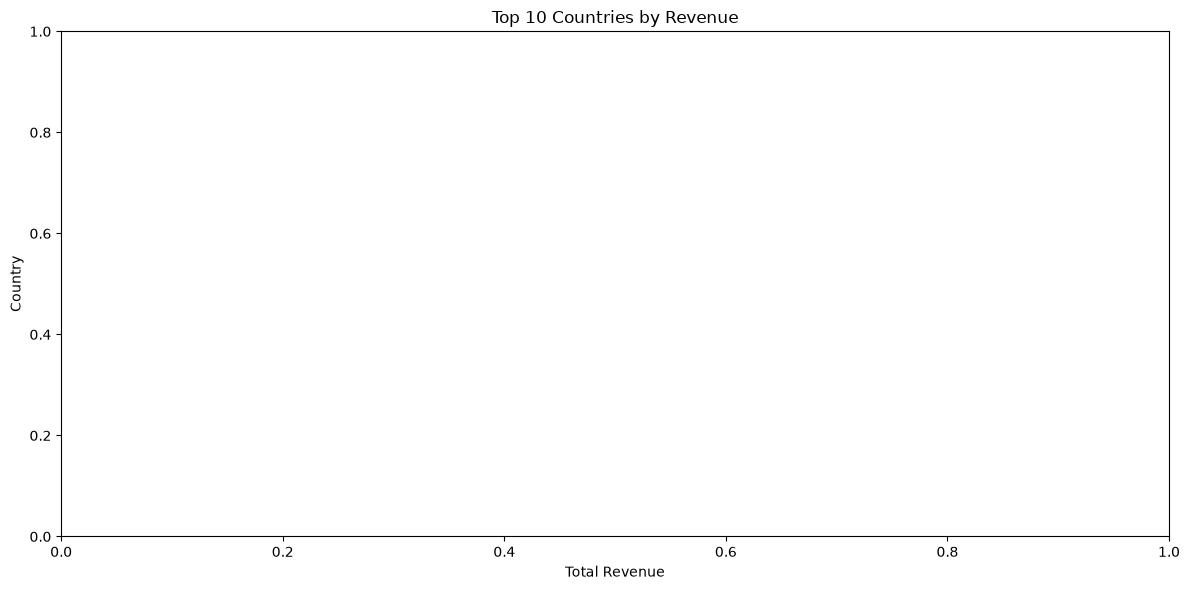

In [19]:
top_countries = country_analysis.head(10).reset_index()
plt.figure(figsize=(12, 6))
sns.barplot(
data=top_countries,
x="total_revenue",
y="Country")
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [20]:
top_order_countries = (
country_analysis["total_orders"].sort_values(ascending=False).head(10))

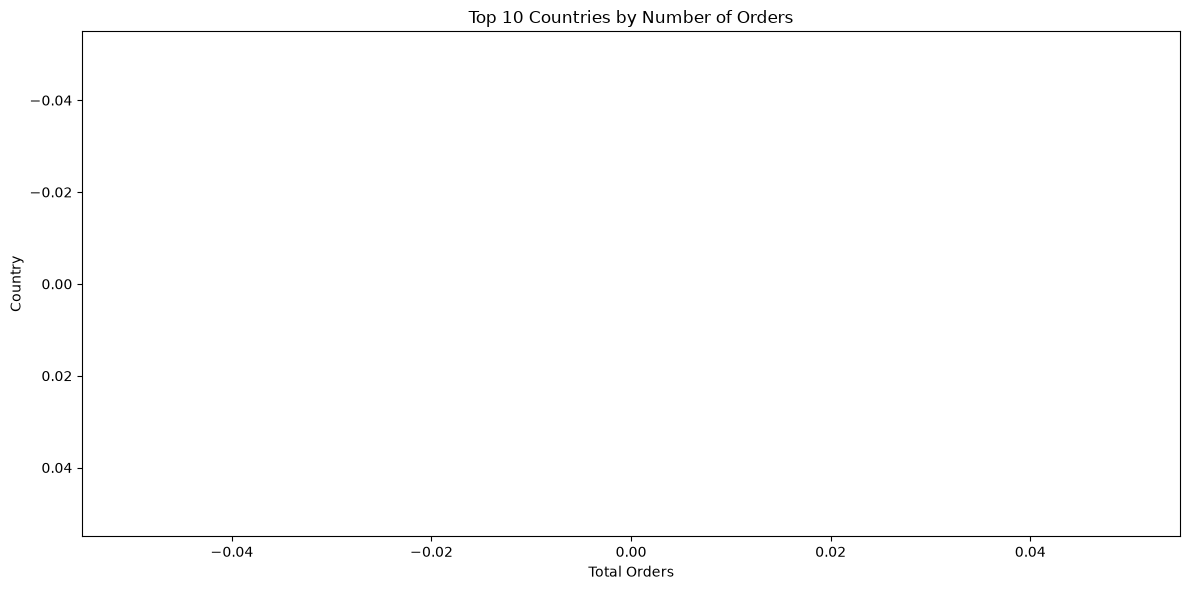

In [21]:
plt.figure(figsize=(12, 6))
plt.barh(
top_order_countries.index,
top_order_countries.values)
plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("Total Orders")
plt.ylabel("Country")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [22]:
country_analysis["revenue_percentage"] = (
country_analysis["total_revenue"]/ country_analysis["total_revenue"].sum()) * 100
print(
country_analysis[
["total_revenue", "revenue_percentage"]].head(10).round(2))

Empty DataFrame
Columns: [total_revenue, revenue_percentage]
Index: []


In [23]:
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M").astype(str)
monthly_sales = (
df.groupby("YearMonth").agg(
total_revenue=("Revenue", "sum"),
total_orders=("InvoiceNo", "nunique"),
total_quantity=("Quantity", "sum")).reset_index())
print(monthly_sales)

Empty DataFrame
Columns: [YearMonth, total_revenue, total_orders, total_quantity]
Index: []


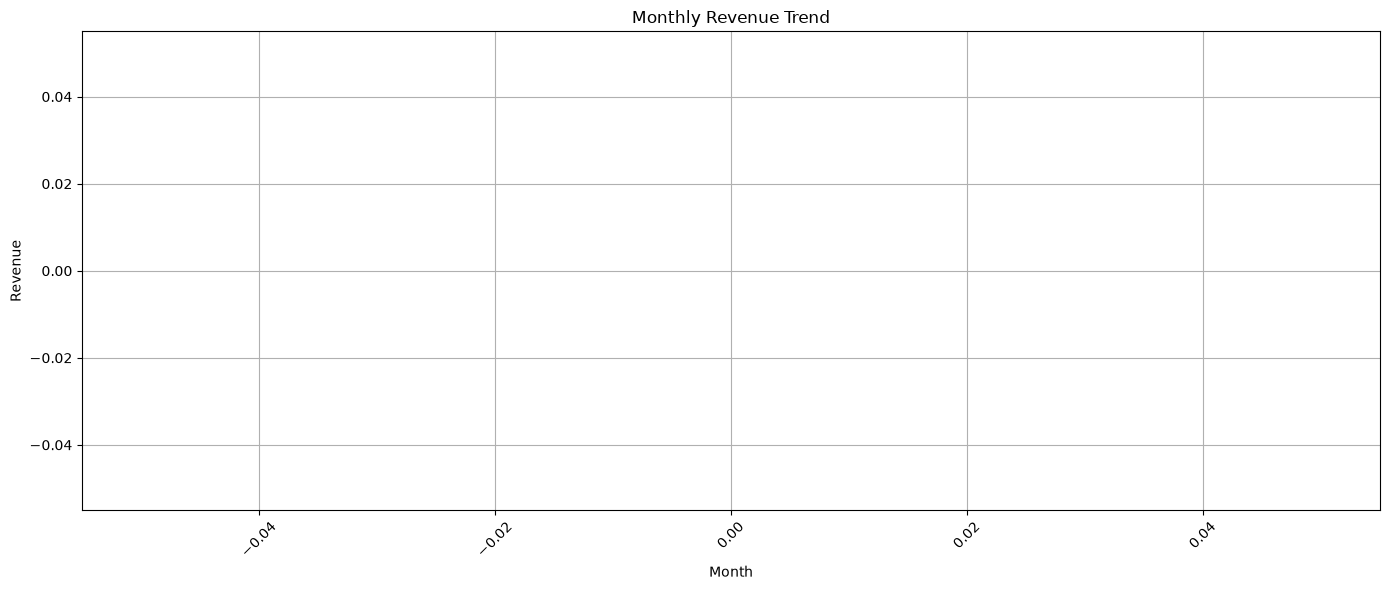

In [24]:
plt.figure(figsize=(14, 6))
plt.plot(
monthly_sales["YearMonth"],
monthly_sales["total_revenue"],
marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
df["Date"] = df["InvoiceDate"].dt.date
daily_sales = (
df.groupby("Date")["Revenue"].sum().reset_index())
print(daily_sales.head(10))

Empty DataFrame
Columns: [Date, Revenue]
Index: []


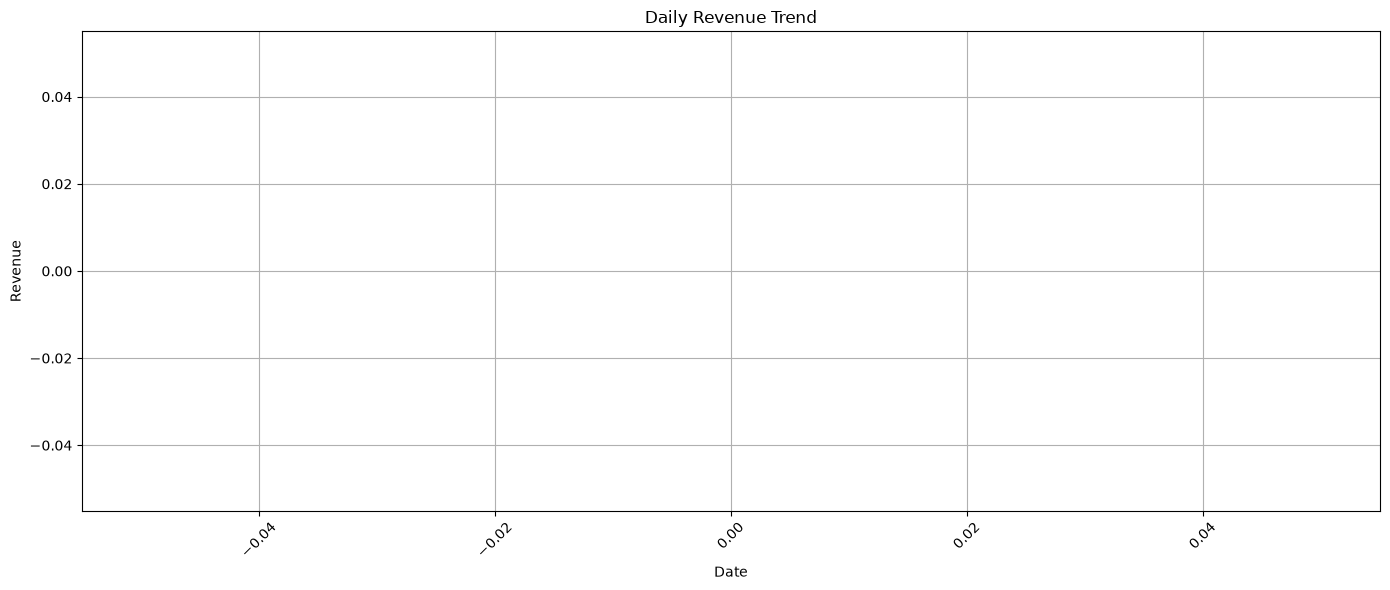

In [26]:
plt.figure(figsize=(14, 6))
plt.plot(
daily_sales["Date"],
daily_sales["Revenue"])
plt.title("Daily Revenue Trend")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [29]:
print("Daily Sales Shape:", daily_sales.shape)
print(daily_sales.head())
print("Missing Revenue:", daily_sales["Revenue"].isnull().sum())
print("Total Revenue:", daily_sales["Revenue"].sum())

Daily Sales Shape: (0, 2)
Empty DataFrame
Columns: [Date, Revenue]
Index: []
Missing Revenue: 0
Total Revenue: 0


In [30]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce")

In [31]:
df = df.dropna(subset=["InvoiceDate", "Revenue"]).copy()

In [33]:
df["Date"] = df["InvoiceDate"].dt.date

In [34]:
daily_sales = (
df.groupby("Date")["Revenue"].sum().reset_index())
print("Daily Sales Shape:", daily_sales.shape)
print(daily_sales.head())

Daily Sales Shape: (0, 2)
Empty DataFrame
Columns: [Date, Revenue]
Index: []


In [35]:
if not daily_sales.empty:

    best_day = daily_sales.loc[daily_sales["Revenue"].idxmax()]
    worst_day = daily_sales.loc[daily_sales["Revenue"].idxmin()]

    print("Best Sales Day:")
    print(best_day)

    print("\nLowest Sales Day:")
    print(worst_day)

else:
    print("No daily sales data available!")

No daily sales data available!


In [36]:
print("Main Dataset Shape:", df.shape)
print(df[["InvoiceDate", "Revenue"]].head(10))
print(df["InvoiceDate"].dtype)

Main Dataset Shape: (0, 11)
Empty DataFrame
Columns: [InvoiceDate, Revenue]
Index: []
datetime64[s]


In [37]:
correlation = df[
["Quantity", "UnitPrice", "Revenue"]].corr()
print(correlation)

           Quantity  UnitPrice  Revenue
Quantity        NaN        NaN      NaN
UnitPrice       NaN        NaN      NaN
Revenue         NaN        NaN      NaN


c:\Users\pantv\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\matrix.py:202: RuntimeWarning: All-NaN slice encountered
  vmin = np.nanmin(calc_data)
c:\Users\pantv\AppData\Local\Programs\Python\Python314\Lib\site-packages\seaborn\matrix.py:207: RuntimeWarning: All-NaN slice encountered
  vmax = np.nanmax(calc_data)


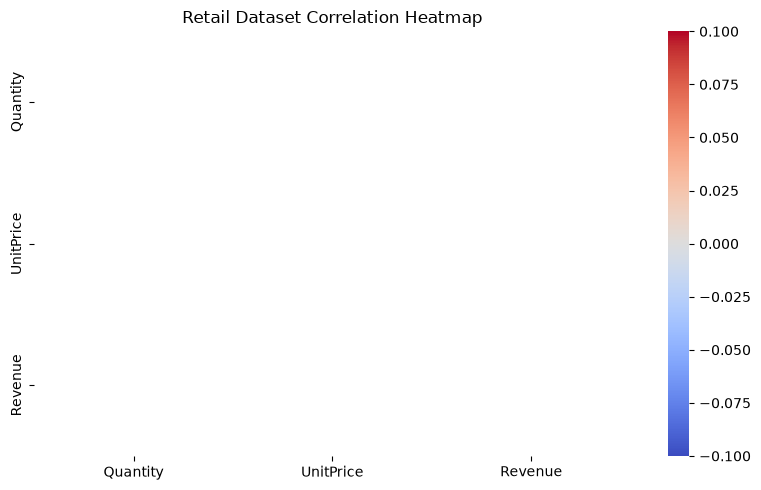

In [38]:
plt.figure(figsize=(8, 5))
sns.heatmap(
correlation,
annot=True,
cmap="coolwarm",
fmt=".2f")
plt.title("Retail Dataset Correlation Heatmap")
plt.tight_layout()
plt.show()